### Imports and paths

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler

DATA_DIR = Path("../data/raw")
PROC_DIR = Path("../data/processed"); PROC_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR  = Path("../figures");        FIG_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 30)

### Sensor names

In [2]:
sensor_map = {
    "s1": "T2_fan_inlet_temp", "s2": "T24_LPC_outlet_temp", "s3": "T30_HPC_outlet_temp",
    "s4": "T50_LPT_outlet_temp", "s5": "P2_fan_inlet_pressure", "s6": "P15_bypass_duct_pressure",
    "s7": "P30_HPC_outlet_pressure", "s8": "Nf_fan_speed", "s9": "Nc_core_speed",
    "s10": "epr_engine_pressure_ratio", "s11": "Ps30_HPC_static_pressure",
    "s12": "phi_fuel_flow_to_Ps30", "s13": "NRf_corrected_fan_speed",
    "s14": "NRc_corrected_core_speed", "s15": "BPR_bypass_ratio",
    "s16": "farB_burner_fuel_air_ratio", "s17": "htBleed_bleed_enthalpy",
    "s18": "Nf_dmd_demanded_fan_speed", "s19": "PCNfR_dmd_demanded_corr_fan_speed",
    "s20": "W31_HPT_coolant_bleed", "s21": "W32_LPT_coolant_bleed",
}
cols = ["unit", "cycle", "op1", "op2", "op3"] + list(sensor_map)

### Load the data and add RUL

In [3]:
df = pd.read_csv(DATA_DIR / "train_FD001.txt", sep=r"\s+", header=None, names=cols)

RUL_CAP = 125
df["RUL"]     = df.groupby("unit")["cycle"].transform("max") - df["cycle"]
df["RUL_cap"] = df["RUL"].clip(upper=RUL_CAP)

print("Shape:", df.shape, "| engines:", df["unit"].nunique())

Shape: (20631, 28) | engines: 100


### Apply sensor selection rule

In [4]:
sensors = list(sensor_map)
std  = df[sensors].std()
nuni = df[sensors].nunique()

keep = [s for s in sensors if std[s] >= 1e-6 and nuni[s] >= 3]
EXP4_KEEP = ["s2","s3","s4","s7","s8","s9","s11","s12","s13","s14","s15","s17","s20","s21"]

assert keep == EXP4_KEEP, "Sensor set differs from Experiment 4!"
print("Kept", len(keep), "sensors:", keep)

Kept 14 sensors: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


### Why covariance-based PCA would mislead

In [6]:
X = df[keep].to_numpy(dtype=float, copy=True)
n, p = X.shape

var = pd.Series(X.var(axis=0, ddof=1), index=keep)
share = (var / var.sum() * 100).sort_values(ascending=False)

print(f"n = {n}, p = {p}")
print("Share of TOTAL raw variance (%):")
print(share.round(2))
print(f"\ns9 + s14 together: {share[['s9','s14']].sum():.1f}% of total variance")

n = 20631, p = 14
Share of TOTAL raw variance (%):
s9     50.05
s14    37.35
s4      8.32
s3      3.86
s17     0.25
s7      0.08
s12     0.06
s2      0.03
s11     0.01
s20     0.00
s21     0.00
s13     0.00
s8      0.00
s15     0.00
dtype: float64

s9 + s14 together: 87.4% of total variance


#### Teaching point: 

Look at how much of the total raw variance comes from s9 and s14 together. If that share is large, covariance-based PCA would make PC1 essentially "core speed", and Experiment 4 showed those are the weakest RUL trackers (|r| = 0.46 and 0.37). That's a units effect, not physics.

### Standardise by hand and check against scikit-learn

In [7]:
mu    = X.mean(axis=0)
sigma = X.std(axis=0, ddof=1)          # sample std, as in Exp 4
Z     = (X - mu) / sigma

Z_sk = StandardScaler().fit_transform(X)   # uses ddof = 0 (population std)

ratio = Z / Z_sk
print("Z / Z_sklearn  min, max :", ratio.min().round(8), ratio.max().round(8))
print("sqrt((n-1)/n)           :", round(np.sqrt((n - 1) / n), 8))

Z / Z_sklearn  min, max : 0.99997576 0.99997576
sqrt((n-1)/n)           : 0.99997576


#### Teaching point: 

StandardScaler divides by n, not n−1, so the two versions differ by a constant factor sqrt{(n-1)/n} = 0.99998. Scaling every column by the same constant doesn't change any eigenvector, so the principal directions are identical. Only the eigenvalues are scaled by (n−1)/n.

### Check that cov(Z) = R

In [8]:
R_from_Z = (Z.T @ Z) / (n - 1)
R_pandas = df[keep].corr().to_numpy()

print("Column means ~0   :", np.allclose(Z.mean(axis=0), 0))
print("Column stds = 1   :", np.allclose(Z.std(axis=0, ddof=1), 1))
print("max |Z'Z/(n-1) - R|:", np.abs(R_from_Z - R_pandas).max())
print("trace             :", np.trace(R_from_Z).round(6), "(= p)")

Column means ~0   : True
Column stds = 1   : True
max |Z'Z/(n-1) - R|: 9.285822111237962e-12
trace             : 14.0 (= p)


### Save the clean data and Z for later steps

In [9]:
clean = df[["unit", "cycle", "RUL", "RUL_cap"] + keep].copy()
clean.to_csv(PROC_DIR / "fd001_clean.csv", index=False)

np.save(PROC_DIR / "Z.npy", Z)
pd.Series(mu, index=keep).to_csv(PROC_DIR / "mu.csv")
pd.Series(sigma, index=keep).to_csv(PROC_DIR / "sigma.csv")
print("Saved:", clean.shape, Z.shape)

Saved: (20631, 18) (20631, 14)


### Eigen-decomposition of R

In [10]:
R = (Z.T @ Z) / (n - 1)

eigvals, eigvecs = np.linalg.eigh(R)          # eigh: symmetric matrix, ascending order
order   = np.argsort(eigvals)[::-1]           # sort descending
lam     = eigvals[order]
V       = eigvecs[:, order]

pc_names = [f"PC{k+1}" for k in range(p)]
pd.DataFrame({"eigenvalue": lam,
              "var_%": lam / lam.sum() * 100,
              "cum_%": np.cumsum(lam) / lam.sum() * 100},
             index=pc_names).round(3)

,eigenvalue,var_%,cum_%
PC1,8.995,64.251,64.251
PC2,2.096,14.971,79.222
PC3,0.414,2.958,82.179
PC4,0.368,2.631,84.810
PC5,0.348,2.488,87.298
PC6,0.306,2.187,89.485
PC7,0.290,2.070,91.555
PC8,0.255,1.824,93.380
PC9,0.206,1.473,94.853
PC10,0.196,1.400,96.253


Why sort: eigh returns eigenvalues in ascending order. PCA needs the largest first.

### Check the spectral theorem

In [11]:
Lam = np.diag(lam)

print("R v = λ v (all k)     :", np.allclose(R @ V, V @ Lam))
print("V orthonormal (V'V=I) :", np.allclose(V.T @ V, np.eye(p)))
print("R = V Λ V'            :", np.allclose(V @ Lam @ V.T, R))
print("sum λ  = trace(R)     :", lam.sum().round(6))
print("prod λ = det(R)       :", f"{np.prod(lam):.3e}", "vs", f"{np.linalg.det(R):.3e}")
print("λ_min, λ_max          :", lam.min().round(5), lam.max().round(5))
print("Condition number κ(R) :", (lam.max() / lam.min()).round(1))

R v = λ v (all k)     : True
V orthonormal (V'V=I) : True
R = V Λ V'            : True
sum λ  = trace(R)     : 14.0
prod λ = det(R)       : 1.197e-07 vs 1.197e-07
λ_min, λ_max          : 0.02927 8.99508
Condition number κ(R) : 307.3


### The SVD route

In [12]:
U, svals, Vt = np.linalg.svd(Z, full_matrices=False)
lam_svd = svals**2 / (n - 1)
V_svd   = Vt.T

print("max |λ_eig - λ_svd|           :", np.abs(lam - lam_svd).max())
# eigenvectors are unique only up to sign -> compare |dot product|
align = np.abs(np.sum(V * V_svd, axis=0))
print("|v_eig · v_svd| per component :", align.round(6))

max |λ_eig - λ_svd|           : 3.552713678800501e-15
|v_eig · v_svd| per component : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


#### Teaching point: 

Each ∣veig⋅vsvd∣should be 1. Some raw dot products are −1, because if v is an eigenvector, so is −v. The sign of a principal component is arbitrary. Engineers need to know this before they interpret a loading or build a health index.

### Check against scikit-learn

In [13]:
from sklearn.decomposition import PCA

pca = PCA(n_components=p).fit(Z)

print("max |λ - sklearn explained_variance_| :", np.abs(lam - pca.explained_variance_).max())
print("explained_variance_ratio_ sum         :", pca.explained_variance_ratio_.sum().round(6))
align_sk = np.abs(np.sum(V * pca.components_.T, axis=0))
print("|v_eig · v_sklearn| per component     :", align_sk.round(6))

max |λ - sklearn explained_variance_| : 0.0
explained_variance_ratio_ sum         : 1.0
|v_eig · v_sklearn| per component     : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### Fix a sign convention

In [14]:
# Convention: the largest-magnitude loading of each PC is positive
flip = np.sign(V[np.argmax(np.abs(V), axis=0), np.arange(p)])
V = V * flip

loadings = pd.DataFrame(V, index=keep, columns=pc_names)
loadings.iloc[:, :3].round(3)

,PC1,PC2,PC3
s2,0.273,0.017,-0.188
s3,0.260,0.076,0.935
s4,0.301,0.009,-0.035
s7,-0.298,0.053,0.029
s8,0.282,-0.244,-0.020
s9,0.106,0.644,-0.046
s11,0.309,-0.016,-0.034
s12,-0.304,0.063,0.021
s13,0.281,-0.246,-0.023
s14,0.066,0.667,-0.041


### Scores, and checking they're uncorrelated


In [15]:
T = Z @ V                                   # principal component scores
C_T = (T.T @ T) / (n - 1)

print("var(scores) = λ          :", np.allclose(np.diag(C_T), lam))
print("scores uncorrelated      :", np.allclose(C_T - np.diag(np.diag(C_T)), 0, atol=1e-10))
print("max |off-diagonal cov|   :", f"{np.abs(C_T - np.diag(np.diag(C_T))).max():.2e}")

np.save(PROC_DIR / "V.npy", V)
np.save(PROC_DIR / "lam.npy", lam)
np.save(PROC_DIR / "T.npy", T)

var(scores) = λ          : True
scores uncorrelated      : True
max |off-diagonal cov|   : 2.89e-15


### Teaching point: 

PCA rotates 14 correlated sensors into 14 uncorrelated components. The heatmap of cov⁡(T) would be diagonal, which is the opposite of the Experiment 4 heatmap with its red and blue blocks.

### Scree plot and cumulative variance

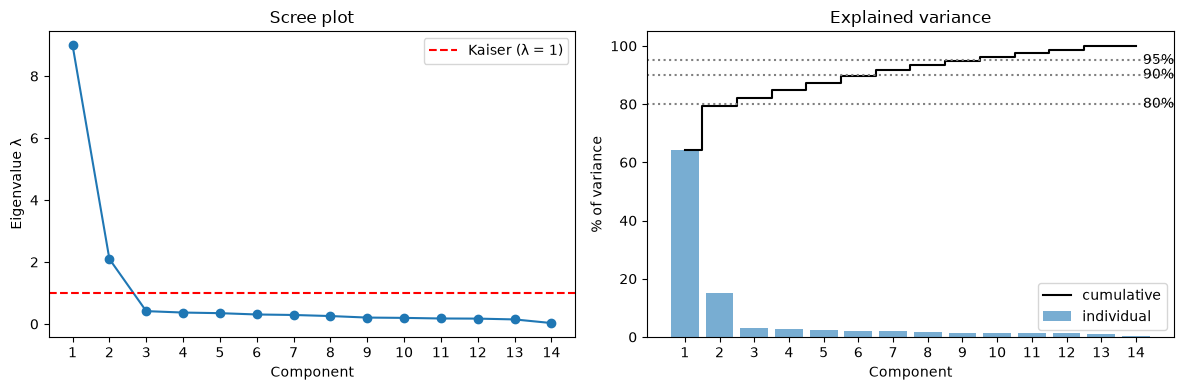

In [16]:
var_pct = lam / lam.sum() * 100
cum_pct = np.cumsum(var_pct)
k_axis  = np.arange(1, p + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_axis, lam, "o-")
ax[0].axhline(1, color="red", ls="--", label="Kaiser (λ = 1)")
ax[0].set_xlabel("Component"); ax[0].set_ylabel("Eigenvalue λ")
ax[0].set_title("Scree plot"); ax[0].set_xticks(k_axis); ax[0].legend()

ax[1].bar(k_axis, var_pct, alpha=0.6, label="individual")
ax[1].step(k_axis, cum_pct, where="mid", color="k", label="cumulative")
for t in (80, 90, 95):
    ax[1].axhline(t, ls=":", color="grey"); ax[1].text(p + 0.2, t, f"{t}%", va="center")
ax[1].set_xlabel("Component"); ax[1].set_ylabel("% of variance")
ax[1].set_title("Explained variance"); ax[1].set_xticks(k_axis); ax[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig01_scree_cumulative.png", dpi=150)
plt.show()

### Broken stick and parallel analysis

In [17]:
# Broken stick
b = np.array([np.sum(1 / np.arange(k, p + 1)) / p for k in range(1, p + 1)]) * 100

# Parallel analysis: shuffle each column independently, recompute eigenvalues
rng = np.random.default_rng(42)
N_REP = 50
lam_rand = np.empty((N_REP, p))
for r in range(N_REP):
    Zs = np.column_stack([rng.permutation(Z[:, j]) for j in range(p)])
    lam_rand[r] = np.sort(np.linalg.eigvalsh((Zs.T @ Zs) / (n - 1)))[::-1]
lam_95 = np.percentile(lam_rand, 95, axis=0)

rules = pd.DataFrame({"λ": lam, "var_%": var_pct, "cum_%": cum_pct,
                      "broken_stick_%": b, "parallel_95%_λ": lam_95},
                     index=pc_names).round(3)
rules["Kaiser"]   = lam > 1
rules["BrokenSt"] = var_pct > b
rules["Parallel"] = lam > lam_95
rules

,λ,var_%,cum_%,broken_stick_%,parallel_95%_λ,Kaiser,BrokenSt,Parallel
PC1,8.995,64.251,64.251,23.225,1.052,True,True,True
PC2,2.096,14.971,79.222,16.083,1.039,True,False,True
PC3,0.414,2.958,82.179,12.511,1.032,False,False,False
PC4,0.368,2.631,84.810,10.130,1.024,False,False,False
PC5,0.348,2.488,87.298,8.344,1.019,False,False,False
PC6,0.306,2.187,89.485,6.916,1.013,False,False,False
PC7,0.290,2.070,91.555,5.725,1.007,False,False,False
PC8,0.255,1.824,93.380,4.705,1.000,False,False,False
PC9,0.206,1.473,94.853,3.812,0.995,False,False,False
PC10,0.196,1.400,96.253,3.019,0.990,False,False,False


Why shuffle: shuffling each column separately keeps every sensor's distribution but destroys all correlation between sensors. Any eigenvalue that doesn't beat the shuffled version is just what you'd get by chance.

### Summary of the selection rules

In [18]:
def first_k(cond):            # number of leading components that satisfy cond
    return int(np.argmin(cond)) if not cond.all() else p

summary = pd.Series({
    "Kaiser (λ > 1)":         first_k(rules["Kaiser"].to_numpy()),
    "Broken stick":           first_k(rules["BrokenSt"].to_numpy()),
    "Parallel analysis":      first_k(rules["Parallel"].to_numpy()),
    "80% cumulative":         int(np.argmax(cum_pct >= 80) + 1),
    "90% cumulative":         int(np.argmax(cum_pct >= 90) + 1),
    "95% cumulative":         int(np.argmax(cum_pct >= 95) + 1),
}, name="k")
summary

Kaiser (λ > 1)        2
Broken stick          1
Parallel analysis     2
80% cumulative        3
90% cumulative        7
95% cumulative       10
Name: k, dtype: int64

### Reconstruction error, checking Eckart–Young

In [19]:
rows = []
for k in range(1, p + 1):
    Zk  = T[:, :k] @ V[:, :k].T
    err = np.sum((Z - Zk) ** 2) / (n - 1)
    rows.append({"k": k, "recon_error": err, "sum_dropped_λ": lam[k:].sum()})
recon = pd.DataFrame(rows).set_index("k")
print("Eckart–Young holds:", np.allclose(recon["recon_error"], recon["sum_dropped_λ"]))
recon.round(4)

Eckart–Young holds: True


,recon_error,sum_dropped_λ
k,,
1,5.0049,5.0049
2,2.9090,2.9090
3,2.4949,2.4949
4,2.1266,2.1266
5,1.7782,1.7782
6,1.4721,1.4721
7,1.1822,1.1822
8,0.9268,0.9268
9,0.7206,0.7206


### The smallest component, where near-collinearity comes from

In [20]:
v14 = pd.Series(V[:, -1], index=keep).sort_values(key=np.abs, ascending=False)
print(f"PC14: λ = {lam[-1]:.5f}  (variance of this sensor combination)")
v14.round(3)

PC14: λ = 0.02927  (variance of this sensor combination)


s9     0.713
s14   -0.701
s8    -0.017
s12    0.015
s13   -0.015
s11   -0.013
s21    0.009
s4    -0.009
s7     0.007
s15   -0.005
s20    0.003
s17   -0.003
s2    -0.003
s3    -0.001
dtype: float64

### Save

In [21]:
rules.to_csv(PROC_DIR / "pca_k_selection.csv")
recon.to_csv(PROC_DIR / "pca_reconstruction_error.csv")

### Loading bar plots for PC1 and PC2

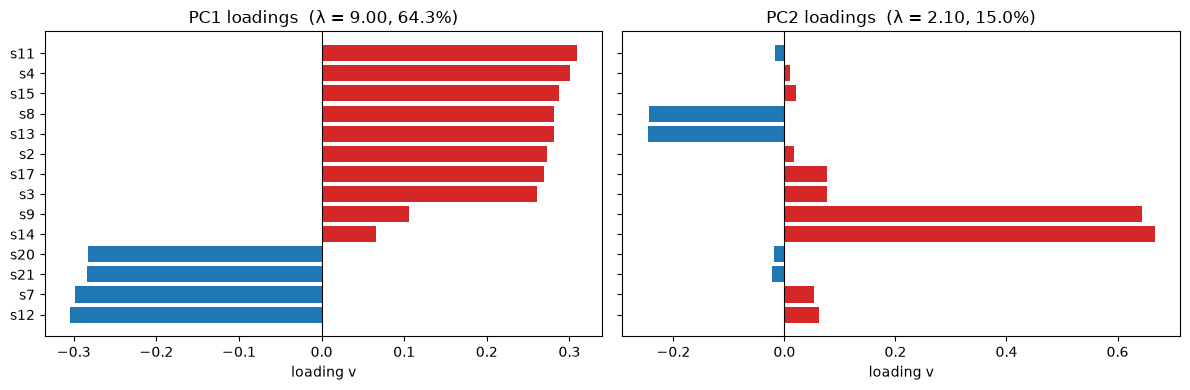

In [46]:
K = 2
fig, axes = plt.subplots(1, K, figsize=(12, 4), sharey=True)
for k, ax in enumerate(axes):
    v = loadings[pc_names[k]].sort_values()
    ax.barh(v.index, v.values, color=["tab:blue" if x < 0 else "tab:red" for x in v.values])
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"{pc_names[k]} loadings  (λ = {lam[k]:.2f}, {var_pct[k]:.1f}%)")
    ax.set_xlabel("loading v")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig02_loadings_pc1_pc2.png", dpi=150)
plt.show()

### Correlation loadings and communalities

In [23]:
corr_load = loadings.iloc[:, :K] * np.sqrt(lam[:K])
corr_load.columns = [f"r_{c}" for c in corr_load.columns]

# check against the direct correlation between each z_j and each score t_k
direct = np.array([[np.corrcoef(Z[:, j], T[:, k])[0, 1] for k in range(K)] for j in range(p)])
print("max |v√λ - corr(z, t)| :", np.abs(corr_load.to_numpy() - direct).max())

corr_load["communality_k2"] = (corr_load ** 2).sum(axis=1)
corr_load["name"] = [sensor_map[s] for s in keep]
corr_load.sort_values("communality_k2").round(3)

max |v√λ - corr(z, t)| : 7.771561172376096e-16


,r_PC1,r_PC2,communality_k2,name
s3,0.780,0.110,0.621,T30_HPC_outlet_temp
s17,0.808,0.112,0.665,htBleed_bleed_enthalpy
s2,0.820,0.025,0.673,T24_LPC_outlet_temp
s20,-0.848,-0.026,0.720,W31_HPT_coolant_bleed
s21,-0.851,-0.033,0.725,W32_LPT_coolant_bleed
s15,0.861,0.030,0.742,BPR_bypass_ratio
s7,-0.895,0.076,0.807,P30_HPC_outlet_pressure
s4,0.903,0.014,0.816,T50_LPT_outlet_temp
s13,0.844,-0.357,0.839,NRf_corrected_fan_speed
s8,0.845,-0.354,0.839,Nf_fan_speed


### Correlation circle

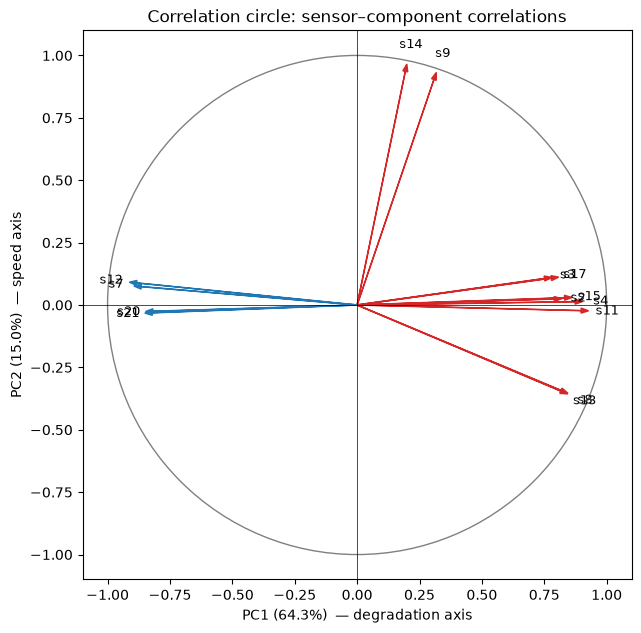

In [24]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
for s, (x, y) in corr_load[["r_PC1", "r_PC2"]].iterrows():
    ax.arrow(0, 0, x, y, head_width=0.02, length_includes_head=True,
             color="tab:red" if x > 0 else "tab:blue")
    ax.text(x * 1.08, y * 1.08, s, fontsize=9, ha="center", va="center")
ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal")
ax.set_xlabel(f"PC1 ({var_pct[0]:.1f}%)  — degradation axis")
ax.set_ylabel(f"PC2 ({var_pct[1]:.1f}%)  — speed axis")
ax.set_title("Correlation circle: sensor–component correlations")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig03_correlation_circle.png", dpi=150)
plt.show()

How to read it: the closer an arrow reaches the circle, the better the two components represent that sensor. Arrows pointing the same way are positively correlated sensors. Arrows pointing opposite ways are negatively correlated. Arrows at 90° are roughly uncorrelated.

### Biplot of scores coloured by RUL, with sensor arrows

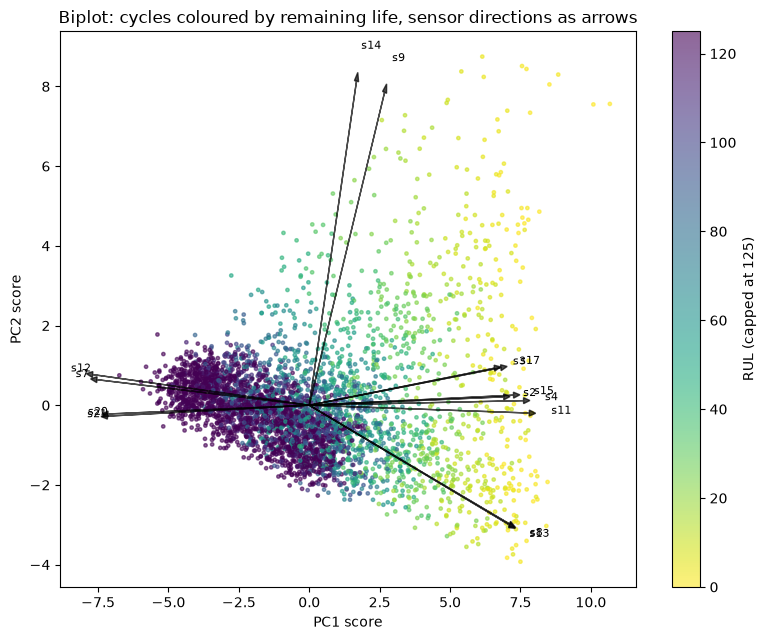

In [29]:
rul_cap = df["RUL_cap"].to_numpy()
idx = np.random.default_rng(0).choice(n, 4000, replace=False)   # subsample for clarity

fig, ax = plt.subplots(figsize=(8, 6.5))
sc = ax.scatter(T[idx, 0], T[idx, 1], c=rul_cap[idx], cmap="viridis_r", s=6, alpha=0.6)
plt.colorbar(sc, label=f"RUL (capped at {RUL_CAP})")

scale = 0.9 * np.abs(T[:, :2]).max(axis=0).min()
for s, (x, y) in corr_load[["r_PC1", "r_PC2"]].iterrows():
    ax.arrow(0, 0, x * scale, y * scale, color="k", alpha=0.7, head_width=0.15)
    ax.text(x * scale * 1.1, y * scale * 1.1, s, fontsize=8)
ax.set_xlabel("PC1 score"); ax.set_ylabel("PC2 score")
ax.set_title("Biplot: cycles coloured by remaining life, sensor directions as arrows")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig04_biplot_rul.png", dpi=150)
plt.show()

### Which components track degradation?

In [26]:
pc_rul = pd.DataFrame({
    "λ":          lam,
    "r_RUL":      [np.corrcoef(T[:, k], df["RUL"])[0, 1] for k in range(p)],
    "r_RULcap":   [np.corrcoef(T[:, k], rul_cap)[0, 1]   for k in range(p)],
}, index=pc_names)
pc_rul["|r_RULcap|"] = pc_rul["r_RULcap"].abs()
pc_rul.round(3)

,λ,r_RUL,r_RULcap,|r_RULcap|
PC1,8.995,-0.741,-0.829,0.829
PC2,2.096,-0.165,-0.210,0.210
PC3,0.414,0.013,0.016,0.016
PC4,0.368,0.012,0.013,0.013
PC5,0.348,0.019,0.021,0.021
PC6,0.306,0.007,0.001,0.001
PC7,0.290,-0.010,-0.017,0.017
PC8,0.255,0.024,0.031,0.031
PC9,0.206,0.009,0.007,0.007
PC10,0.196,-0.023,-0.012,0.012


### Save

In [27]:
corr_load.to_csv(PROC_DIR / "pca_correlation_loadings.csv")
pc_rul.to_csv(PROC_DIR / "pca_vs_RUL.csv")

### Build a scores table with smoothing

In [30]:
sc = pd.DataFrame({"unit": df["unit"].to_numpy(), "cycle": df["cycle"].to_numpy(),
                   "RUL": df["RUL"].to_numpy(), "RUL_cap": df["RUL_cap"].to_numpy(),
                   "PC1": T[:, 0], "PC2": T[:, 1]})

W = 10
for c in ["PC1", "PC2"]:
    sc[f"{c}_s"] = sc.groupby("unit")[c].transform(lambda x: x.rolling(W, min_periods=1).mean())

print("raw PC1 noise (std of diff):     ", sc.groupby("unit")["PC1"].diff().std().round(3))
print("smoothed PC1 noise (std of diff):", sc.groupby("unit")["PC1_s"].diff().std().round(3))

raw PC1 noise (std of diff):      0.752
smoothed PC1 noise (std of diff): 0.094


### Trajectories of selected engines in the PC1–PC2 plane

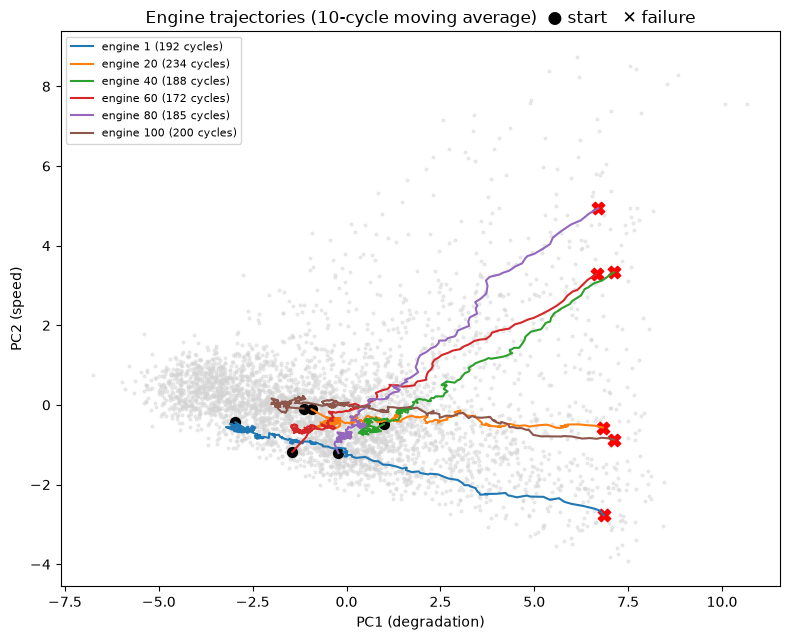

In [31]:
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.scatter(T[idx, 0], T[idx, 1], c="lightgrey", s=4, alpha=0.4)
for u in [1, 20, 40, 60, 80, 100]:
    e = sc[sc["unit"] == u]
    ax.plot(e["PC1_s"], e["PC2_s"], lw=1.5, label=f"engine {u} ({len(e)} cycles)")
    ax.scatter(e["PC1_s"].iloc[0],  e["PC2_s"].iloc[0],  marker="o", s=50, color="k")
    ax.scatter(e["PC1_s"].iloc[-1], e["PC2_s"].iloc[-1], marker="X", s=80, color="red")
ax.set_xlabel("PC1 (degradation)"); ax.set_ylabel("PC2 (speed)")
ax.set_title(f"Engine trajectories ({W}-cycle moving average)  ● start   ✕ failure")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig05_engine_trajectories.png", dpi=150)
plt.show()

### PC1 over life for all 100 engines, aligned at failure

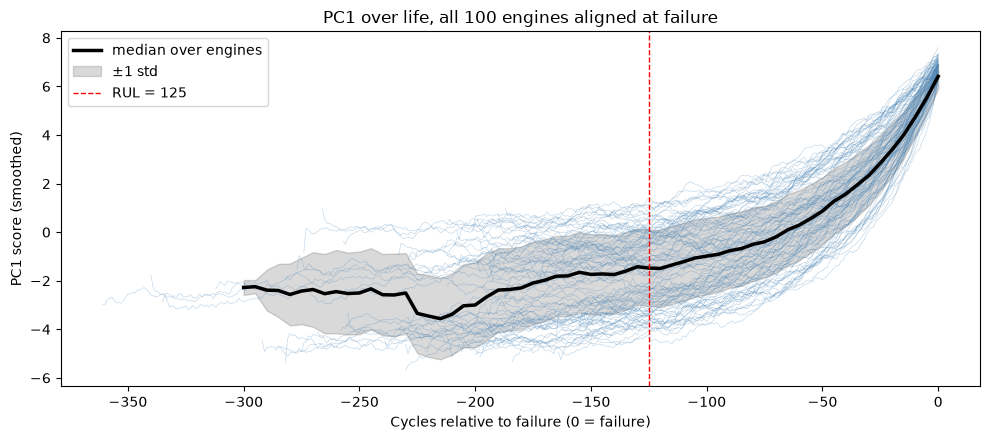

In [32]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for u, e in sc.groupby("unit"):
    ax.plot(-e["RUL"], e["PC1_s"], color="steelblue", lw=0.5, alpha=0.3)

band = sc.assign(bin=(sc["RUL"] // 5) * 5).groupby("bin")["PC1_s"].agg(["median", "std"])
band = band[band.index <= 300]
ax.plot(-band.index, band["median"], color="k", lw=2.5, label="median over engines")
ax.fill_between(-band.index, band["median"] - band["std"], band["median"] + band["std"],
                color="k", alpha=0.15, label="±1 std")
ax.axvline(-RUL_CAP, color="red", ls="--", lw=1, label=f"RUL = {RUL_CAP}")
ax.set_xlabel("Cycles relative to failure (0 = failure)"); ax.set_ylabel("PC1 score (smoothed)")
ax.set_title("PC1 over life, all 100 engines aligned at failure")
ax.legend(); plt.tight_layout()
plt.savefig(FIG_DIR / "fig06_pc1_aligned_at_failure.png", dpi=150)
plt.show()

### Healthy start vs. failure end, as a paired test

In [33]:
from scipy import stats

start = sc[sc["cycle"] <= 10].groupby("unit")[["PC1", "PC2"]].mean()
end   = sc[sc["RUL"]   <  10].groupby("unit")[["PC1", "PC2"]].mean()

summary_se = pd.DataFrame({"start_mean": start.mean(), "start_std": start.std(),
                           "end_mean": end.mean(),     "end_std": end.std()}).round(3)
print(summary_se, "\n")

t_stat, p_val = stats.ttest_rel(end["PC1"], start["PC1"])
print(f"Paired t-test PC1 (end vs start): t = {t_stat:.2f}, p = {p_val:.2e}")
print(f"PC1 rises in {(end['PC1'] > start['PC1']).sum()} of 100 engines")

lev = stats.levene(start["PC2"], end["PC2"])
print(f"PC2 spread start vs end: std {start['PC2'].std():.2f} -> {end['PC2'].std():.2f}, "
      f"Levene p = {lev.pvalue:.2e}")

     start_mean  start_std  end_mean  end_std
PC1      -2.273      1.705     6.759    0.313
PC2      -0.283      0.733     0.958    3.466 

Paired t-test PC1 (end vs start): t = 57.41, p = 8.27e-78
PC1 rises in 100 of 100 engines
PC2 spread start vs end: std 0.73 -> 3.47, Levene p = 6.27e-22


#### Why these tests:

- The paired t-test compares each engine with itself, which removes differences between engines.
- Levene's test checks whether the spread of PC2 differs between the start and end of life. This is the statistical version of the cone you saw in the biplot.

### Do engines fail "up" or "down" in PC2?

In [34]:
end_branch = np.where(end["PC2"] > 0, "core-speed branch (PC2 > 0)", "fan-speed branch (PC2 < 0)")
life = sc.groupby("unit")["cycle"].max()

branch = pd.DataFrame({"branch": end_branch, "end_PC2": end["PC2"], "life": life})
print(branch["branch"].value_counts(), "\n")
print(branch.groupby("branch")["life"].describe()[["count", "mean", "std", "min", "max"]].round(1))

t2, p2 = stats.ttest_ind(*[g["life"] for _, g in branch.groupby("branch")], equal_var=False)
r_life = np.corrcoef(branch["end_PC2"], branch["life"])[0, 1]
print(f"\nWelch t-test on life between branches: p = {p2:.3f}")
print(f"corr(end PC2, engine life) = {r_life:.3f}")

branch
fan-speed branch (PC2 < 0)     51
core-speed branch (PC2 > 0)    49
Name: count, dtype: int64 

                             count   mean   std    min    max
branch                                                       
core-speed branch (PC2 > 0)   49.0  211.6  40.2  137.0  341.0
fan-speed branch (PC2 < 0)    51.0  201.3  51.4  128.0  362.0

Welch t-test on life between branches: p = 0.268
corr(end PC2, engine life) = 0.164


Why: if engines that end on the core-speed branch live longer or shorter than the others, then PC2 carries information about how long an engine lasts, even though it isn't a degradation axis. This sets up a discussion question for students.

### PC1 vs. s11 within each engine

      r_PC1  r_s11
mean -0.880 -0.811
50%  -0.889 -0.816
min  -0.908 -0.870
max  -0.790 -0.676

PC1 beats s11 in 100 of 100 engines


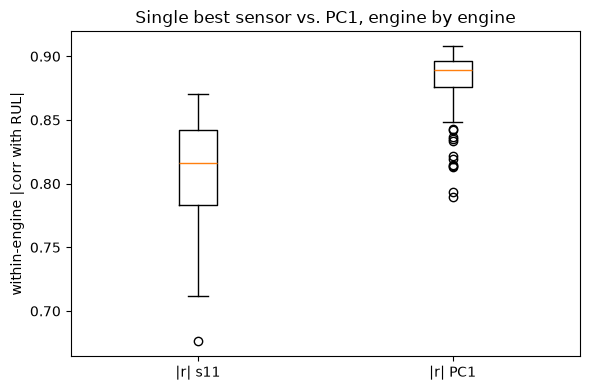

In [35]:
s11_col = keep.index("s11")
sc["z_s11"] = Z[:, s11_col]

within = sc.groupby("unit")[["PC1", "z_s11", "RUL"]].apply(
    lambda g: pd.Series({"r_PC1": g["PC1"].corr(g["RUL"]),
                         "r_s11": g["z_s11"].corr(g["RUL"])}))
print(within.describe().loc[["mean", "50%", "min", "max"]].round(3))
print(f"\nPC1 beats s11 in {(within['r_PC1'].abs() > within['r_s11'].abs()).sum()} of 100 engines")

plt.figure(figsize=(6, 4))
plt.boxplot([within["r_s11"].abs(), within["r_PC1"].abs()], tick_labels=["|r| s11", "|r| PC1"])
plt.ylabel("within-engine |corr with RUL|")
plt.title("Single best sensor vs. PC1, engine by engine")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig07_within_engine_pc1_vs_s11.png", dpi=150)
plt.show()

#### Teaching point: 

PC1 averages 12 noisy sensors that point the same way. If the sensors' noise is roughly independent, averaging reduces it, so PC1 should track wear more cleanly within each engine than any single sensor. This is the main argument for a PCA-based health index.

### Split by engine and fit the scaler and PCA on training engines only

In [36]:
rng = np.random.default_rng(7)
units = df["unit"].unique()
val_units = np.sort(rng.choice(units, 20, replace=False))
is_tr = ~df["unit"].isin(val_units).to_numpy()
is_va = ~is_tr

X_all = df[keep].to_numpy(dtype=float, copy=True)
mu_tr = X_all[is_tr].mean(axis=0)
sd_tr = X_all[is_tr].std(axis=0, ddof=1)
Z_all = (X_all - mu_tr) / sd_tr                      # everyone uses TRAIN statistics

lam_tr, V_tr = np.linalg.eigh(Z_all[is_tr].T @ Z_all[is_tr] / (is_tr.sum() - 1))
v1 = V_tr[:, np.argmax(lam_tr)]
if np.corrcoef(Z_all[is_tr] @ v1, df.loc[is_tr, "RUL_cap"])[0, 1] > 0:
    v1 = -v1                                          # orient: HI rises toward failure

print("validation engines:", val_units.tolist())
print("train cycles:", is_tr.sum(), "| validation cycles:", is_va.sum())
print("|v1_train · v1_all-data| =", round(abs(v1 @ V[:, 0]), 5))

validation engines: [1, 5, 12, 13, 20, 26, 28, 47, 48, 50, 52, 57, 67, 73, 76, 77, 79, 81, 85, 98]
train cycles: 16573 | validation cycles: 4058
|v1_train · v1_all-data| = 0.99992


Why the last line matters: if PC1 from 80 engines is almost identical to PC1 from all 100 (close to 1.0), then the direction is stable. Leakage didn't create it.

### Build the four candidate indicators

In [37]:
s11_j = keep.index("s11")
w_eq  = np.sign(v1) / np.sqrt(p)                       # equal weights, PC1 signs

A_tr = np.column_stack([np.ones(is_tr.sum()), Z_all[is_tr]])
beta, *_ = np.linalg.lstsq(A_tr, df.loc[is_tr, "RUL_cap"].to_numpy(), rcond=None)

raw = pd.DataFrame({
    "PC1":       Z_all @ v1,
    "s11":       Z_all[:, s11_j],                       # rises toward failure
    "EqualAvg":  Z_all @ w_eq,
    "Supervised": -(beta[0] + Z_all @ beta[1:]),        # minus predicted RUL -> rises
})
raw["unit"], raw["cycle"], raw["RUL"], raw["RUL_cap"] = (df["unit"].to_numpy(), df["cycle"].to_numpy(),
                                                          df["RUL"].to_numpy(), df["RUL_cap"].to_numpy())
HI_NAMES = ["PC1", "s11", "EqualAvg", "Supervised"]

# smooth with a TRAILING window (uses only past cycles -> usable online)
for c in HI_NAMES:
    raw[c] = raw.groupby("unit")[c].transform(lambda x: x.rolling(W, min_periods=1).mean())

# rescale to 0 (healthy) ... 1 (failure) using TRAINING engines only
tr = raw[is_tr]
scale = {}
for c in HI_NAMES:
    h0 = tr.loc[tr["cycle"] <= 10, c].mean()
    h1 = tr.loc[tr["RUL"] < 10, c].mean()
    scale[c] = (h0, h1)
    raw[c] = (raw[c] - h0) / (h1 - h0)

print(pd.Series(np.round(np.abs(w_eq @ v1), 4), index=["cos(equal weights, PC1)"]))

cos(equal weights, PC1)    0.9667
dtype: float64


#### Teaching point: 

A trailing moving average only uses cycles that have already happened, so this health index could run live on an engine controller. A centred window would quietly use future data.

### Health-index metrics on the validation engines

In [38]:
from scipy.stats import spearmanr

def hi_metrics(h, frame):
    r_pool = abs(np.corrcoef(h, frame["RUL_cap"])[0, 1])
    mono, trend, starts, ends = [], [], [], []
    for _, g in frame.assign(h=h).groupby("unit"):
        d = np.diff(g["h"].to_numpy())
        mono.append(abs((d > 0).sum() - (d < 0).sum()) / len(d))
        trend.append(spearmanr(g["cycle"], g["h"]).statistic)
        starts.append(g["h"].iloc[:10].mean()); ends.append(g["h"].iloc[-10:].mean())
    starts, ends = np.array(starts), np.array(ends)
    prog = np.exp(-ends.std() / np.abs(ends - starts).mean())
    return {"|r| RUL_cap (pooled)": r_pool, "Monotonicity": np.mean(mono),
            "Trendability (median ρ)": np.median(trend), "Prognosability": prog,
            "HI at failure (mean)": ends.mean(), "HI at failure (std)": ends.std()}

va = raw[is_va]
metrics = pd.DataFrame({c: hi_metrics(va[c].to_numpy(), va) for c in HI_NAMES}).T.round(3)
metrics

,|r| RUL_cap (pooled),Monotonicity,Trendability (median ρ),Prognosability,HI at failure (mean),HI at failure (std)
PC1,0.816,0.381,0.985,0.939,0.997,0.061
s11,0.805,0.192,0.948,0.918,1.012,0.084
EqualAvg,0.839,0.381,0.985,0.921,0.982,0.079
Supervised,0.852,0.387,0.981,0.858,0.972,0.146


### Plot the health indices for validation engines, aligned at failure

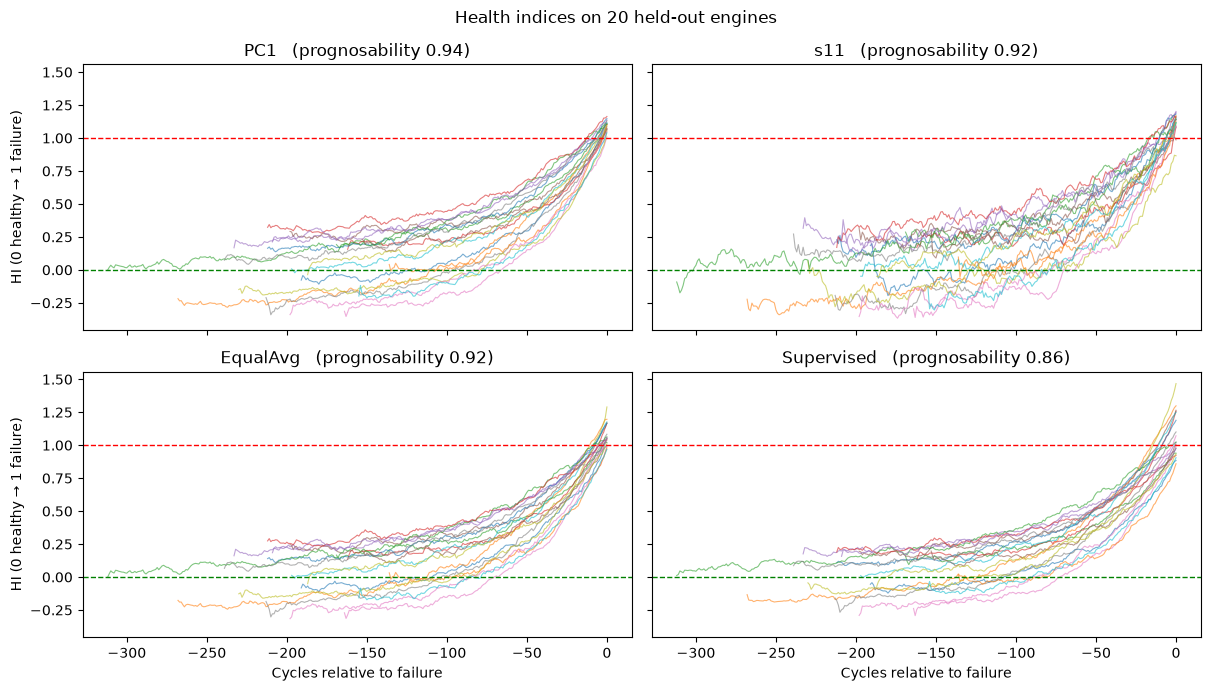

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
for ax, c in zip(axes.ravel(), HI_NAMES):
    for _, g in va.groupby("unit"):
        ax.plot(-g["RUL"], g[c], lw=0.8, alpha=0.6)
    ax.axhline(1, color="red", ls="--", lw=1)
    ax.axhline(0, color="green", ls="--", lw=1)
    ax.set_title(f"{c}   (prognosability {metrics.loc[c, 'Prognosability']:.2f})")
for ax in axes[1, :]:
    ax.set_xlabel("Cycles relative to failure")
for ax in axes[:, 0]:
    ax.set_ylabel("HI (0 healthy → 1 failure)")
plt.suptitle("Health indices on 20 held-out engines")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig08_health_indices_validation.png", dpi=150)
plt.show()

### Turn the health index into a RUL estimate on the official test set

Test engines: 100 | RMSE = 23.3 | MAE = 18.4 | constant-mean baseline RMSE = 40.1


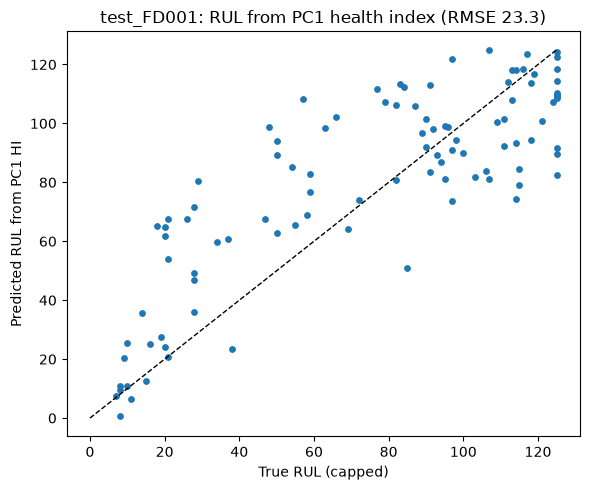

In [43]:
cols_t = ["unit", "cycle", "op1", "op2", "op3"] + list(sensor_map)
test = pd.read_csv(DATA_DIR / "test_FD001.txt", sep=r"\s+", header=None, names=cols_t)
rul_true = pd.read_csv(DATA_DIR / "RUL_FD001.txt", sep=r"\s+", header=None).iloc[:, 0].to_numpy()

Z_te = (test[keep].to_numpy(dtype=float, copy=True) - mu_tr) / sd_tr     # TRAIN statistics
h_te = (pd.Series(Z_te @ v1)
          .groupby(test["unit"].to_numpy())
          .transform(lambda x: x.rolling(W, min_periods=1).mean())
          .to_numpy())
h0, h1 = scale["PC1"]
test["HI"] = (h_te - h0) / (h1 - h0)
hi_last = test.groupby("unit")["HI"].last().to_numpy()

# map HI -> capped RUL with a quadratic fit on TRAINING engines
coef = np.polyfit(raw.loc[is_tr, "PC1"], raw.loc[is_tr, "RUL_cap"], deg=2)
rul_pred = np.clip(np.polyval(coef, hi_last), 0, RUL_CAP)

truth = np.minimum(rul_true, RUL_CAP)
rmse  = np.sqrt(np.mean((rul_pred - truth) ** 2))
mae   = np.mean(np.abs(rul_pred - truth))
rmse0 = np.sqrt(np.mean((truth.mean() - truth) ** 2))      # baseline: always predict the mean
print(f"Test engines: {len(truth)} | RMSE = {rmse:.1f} | MAE = {mae:.1f} | "
      f"constant-mean baseline RMSE = {rmse0:.1f}")

plt.figure(figsize=(6, 5))
plt.scatter(truth, rul_pred, s=15)
plt.plot([0, RUL_CAP], [0, RUL_CAP], "k--", lw=1)
plt.xlabel("True RUL (capped)"); plt.ylabel("Predicted RUL from PC1 HI")
plt.title(f"test_FD001: RUL from PC1 health index (RMSE {rmse:.1f})")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig09_test_rul_from_hi.png", dpi=150)
plt.show()

#### Teaching point: 

Test engines are cut off before failure, so the only information available is their history up to that point. This is the real prognostics problem. The result gives an interpretable baseline that LSTM has to beat.

### Save

In [44]:
metrics.to_csv(PROC_DIR / "hi_metrics_validation.csv")
pd.DataFrame({"unit": np.arange(1, len(truth) + 1), "RUL_true_cap": truth,
              "RUL_pred": rul_pred.round(1), "HI_last": hi_last.round(3)}
            ).to_csv(PROC_DIR / "test_rul_predictions.csv", index=False)
np.save(PROC_DIR / "v1_train.npy", v1)

### Fit a healthy-state PCA (first 50 cycles of the training engines)

In [47]:
HEALTHY_CYC = 50                       # shortest engine life is 128, so the first 50 cycles are safely healthy
hmask = is_tr & (df["cycle"].to_numpy() <= HEALTHY_CYC)

mu_h = X_all[hmask].mean(axis=0)
sd_h = X_all[hmask].std(axis=0, ddof=1)
Zh_all = (X_all - mu_h) / sd_h          # everyone scaled with HEALTHY training statistics
Zh = Zh_all[hmask]

Rh = Zh.T @ Zh / (len(Zh) - 1)
lam_h, V_h = np.linalg.eigh(Rh)
o = np.argsort(lam_h)[::-1]
lam_h, V_h = lam_h[o], V_h[:, o]

# parallel analysis on the healthy data
rng = np.random.default_rng(1)
lam_rand_h = np.array([
    np.sort(np.linalg.eigvalsh(np.corrcoef(
        np.column_stack([rng.permutation(Zh[:, j]) for j in range(p)]), rowvar=False)))[::-1]
    for _ in range(30)])
lam95_h = np.percentile(lam_rand_h, 95, axis=0)

above = lam_h > lam95_h
k_h = max(1, p if above.all() else int(np.argmin(above)))

print("healthy cycles:", hmask.sum(), "| k chosen by parallel analysis:", k_h)
print(pd.DataFrame({"λ_healthy": lam_h, "parallel_95%": lam95_h},
                   index=pc_names).head(6).round(3))
print("\nTop loadings of healthy PC1:")
print(pd.Series(V_h[:, 0], index=keep).sort_values(key=np.abs, ascending=False).head(5).round(3))

healthy cycles: 4000 | k chosen by parallel analysis: 2
     λ_healthy  parallel_95%
PC1      7.153         1.119
PC2      1.239         1.093
PC3      0.731         1.070
PC4      0.671         1.053
PC5      0.638         1.041
PC6      0.587         1.026

Top loadings of healthy PC1:
s13    0.318
s8     0.317
s11    0.310
s12   -0.306
s7    -0.291
dtype: float64


#### Teaching point: 

Compare these eigenvalues with Step 3, where PC1 = 8.995. In healthy engines most of the strong correlation disappears, because the 12 degradation sensors aren't yet moving together. What correlation remains is likely the definitional s9–s14 link. Degradation is what creates the correlation structure.

### T² and SPE for every cycle, with control limits

In [48]:
from scipy.stats import chi2

Vk = V_h[:, :k_h]
Tk = Zh_all @ Vk
T2  = np.sum(Tk**2 / lam_h[:k_h], axis=1)
SPE = np.sum((Zh_all - Tk @ Vk.T) ** 2, axis=1)

mon = pd.DataFrame({"unit": df["unit"].to_numpy(), "cycle": df["cycle"].to_numpy(),
                    "RUL": df["RUL"].to_numpy(), "T2": T2, "SPE": SPE})
for c in ["T2", "SPE"]:
    mon[f"{c}_s"] = mon.groupby("unit")[c].transform(lambda x: x.rolling(W, min_periods=1).mean())

lim = {c: np.percentile(mon.loc[hmask, f"{c}_s"], 99) for c in ["T2", "SPE"]}
print("Control limits (99th pct, healthy train, smoothed):", {c: round(v, 3) for c, v in lim.items()})
print(f"Raw T² 99th pct (empirical) = {np.percentile(T2[hmask], 99):.2f}  vs  χ²_{k_h} theory = {chi2.ppf(0.99, k_h):.2f}")

Control limits (99th pct, healthy train, smoothed): {'T2': np.float64(4.662), 'SPE': np.float64(8.494)}
Raw T² 99th pct (empirical) = 6.56  vs  χ²_2 theory = 9.21


The limits are computed on the smoothed statistics, because the alarms below use smoothed values. The X² comparison checks how close the healthy data is to Gaussian.

### Alarm rule and lead time on the validation engines

In [49]:
M = 5                                    # persistence: M consecutive cycles above the limit

def first_alarm(g, c):
    exc = (g[f"{c}_s"] > lim[c]).astype(int)
    hit = np.where(exc.rolling(M).sum().to_numpy() == M)[0]
    if len(hit) == 0:
        return pd.Series({"alarm_cycle": np.nan, "lead_time": np.nan})
    i = hit[0]
    return pd.Series({"alarm_cycle": g["cycle"].iloc[i], "lead_time": g["RUL"].iloc[i]})

alarms = {}
for c in ["T2", "SPE"]:
    a = mon[is_va].groupby("unit")[["cycle", "RUL", f"{c}_s"]].apply(lambda g: first_alarm(g, c))
    alarms[c] = a

summ = pd.DataFrame({c: {
    "engines alarmed (of 20)":          a["alarm_cycle"].notna().sum(),
    "early alarms (cycle ≤ 50)":        (a["alarm_cycle"] <= HEALTHY_CYC).sum(),
    "median lead time (cycles)":        a["lead_time"].median(),
    "min lead time":                    a["lead_time"].min(),
    "max lead time":                    a["lead_time"].max()} for c, a in alarms.items()}).T
summ

,engines alarmed (of 20),early alarms (cycle ≤ 50),median lead time (cycles),min lead time,max lead time
T2,20.0,1.0,72.0,27.0,167.0
SPE,5.0,0.0,19.0,12.0,57.0


Why persistence: a single cycle above the limit is often noise, and Exp 4 showed how one glitch can flip a correlation. Requiring M consecutive exceedances trades a few cycles of lead time for far fewer false alarms. Early alarms (alarms during the first 50 healthy cycles) count as false alarms.

### Monitoring charts

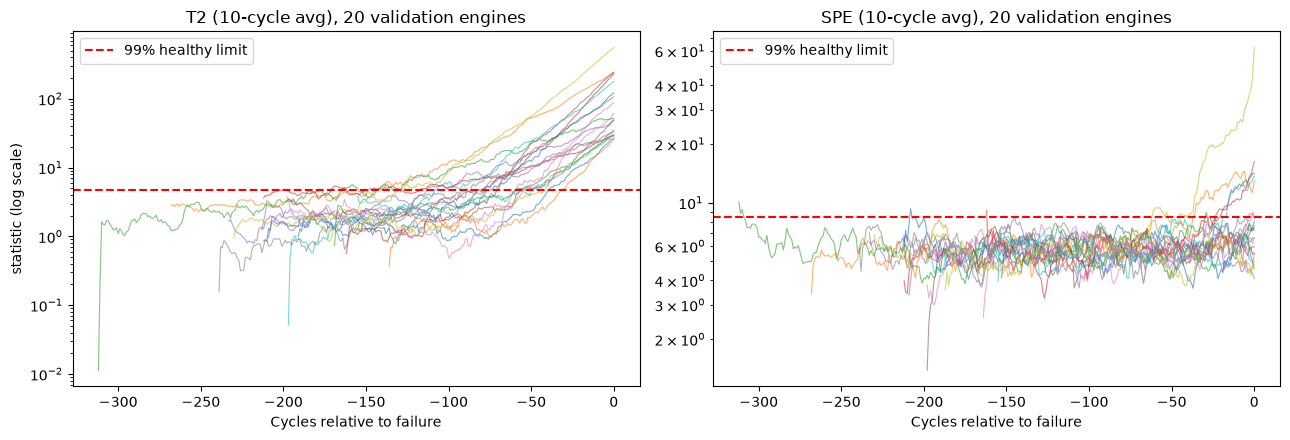

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, c in zip(axes, ["T2", "SPE"]):
    for _, g in mon[is_va].groupby("unit"):
        ax.plot(-g["RUL"], g[f"{c}_s"], lw=0.8, alpha=0.6)
    ax.axhline(lim[c], color="red", ls="--", label="99% healthy limit")
    ax.set_yscale("log")
    ax.set_xlabel("Cycles relative to failure")
    ax.set_title(f"{c} ({W}-cycle avg), 20 validation engines")
    ax.legend()
axes[0].set_ylabel("statistic (log scale)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig10_t2_spe_monitoring.png", dpi=150)
plt.show()

### Which sensors cause the alarm?

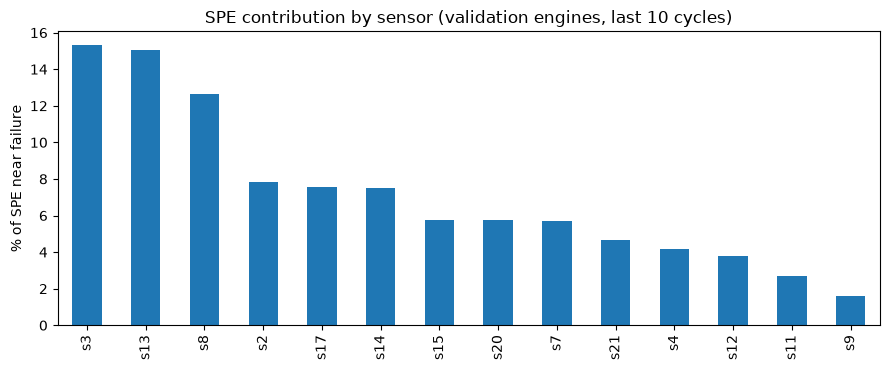

,healthy (mean e²),near failure (mean e²),share_at_failure_%
s3,0.711,1.645,15.306
s13,0.263,1.616,15.037
s8,0.266,1.361,12.666
s2,0.560,0.841,7.824
s17,0.590,0.811,7.547
s14,0.120,0.808,7.520
s15,0.513,0.618,5.751
s20,0.507,0.616,5.729
s7,0.379,0.612,5.695
s21,0.503,0.500,4.652


In [51]:
resid = Zh_all - Tk @ Vk.T
early_va = is_va & (df["cycle"].to_numpy() <= HEALTHY_CYC)
late_va  = is_va & (df["RUL"].to_numpy() < 10)

contrib = pd.DataFrame({
    "healthy (mean e²)":       (resid[early_va] ** 2).mean(axis=0),
    "near failure (mean e²)":  (resid[late_va]  ** 2).mean(axis=0),
}, index=keep)
contrib["share_at_failure_%"] = contrib["near failure (mean e²)"] / contrib["near failure (mean e²)"].sum() * 100
contrib = contrib.sort_values("share_at_failure_%", ascending=False)

contrib["share_at_failure_%"].plot.bar(figsize=(9, 3.8))
plt.ylabel("% of SPE near failure")
plt.title("SPE contribution by sensor (validation engines, last 10 cycles)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig11_spe_contributions.png", dpi=150)
plt.show()
contrib.round(3)

#### Teaching point: 

Compare this ranking with Exp 4's sensor-vs-RUL table (s11, s4, s12, s7 at the top). If the same sensors dominate here, two unrelated methods agree on where the fault is: one uses RUL labels and correlation, the other uses no labels at all. That agreement points to the HPC, which is FD001's actual fault location.

### Save

In [52]:
mon.to_csv(PROC_DIR / "t2_spe_by_cycle.csv", index=False)
pd.concat(alarms, axis=1).to_csv(PROC_DIR / "alarms_validation.csv")
summ.to_csv(PROC_DIR / "alarm_summary.csv")
contrib.to_csv(PROC_DIR / "spe_contributions.csv")
np.save(PROC_DIR / "V_healthy.npy", V_h)

### Conclusions

1. Raw-unit PCA is dominated by units: s9 + s14 = 87.4% of variance; s11 (best RUL sensor) = 0.01%. Standardise first.

2. Two components carry the signal (79.2%): PC1 = degradation (64.3%), PC2 = core vs fan speed (15.0%). Kaiser and parallel analysis agree on k = 2; Eckart–Young holds exactly.

3. PC14 ≈ (z9 − z14)/√2 with λ = 0.029 is the sole source of near-collinearity (κ = 307).

4. PCA never saw RUL, yet PC1 has |r| = 0.829 with capped RUL vs 0.775 for s11. PC1 rises in 100/100 engines.

5. Engines start spread (PC1 std 1.71) but fail at one level (std 0.31); PC2 fans out (Levene p = 6e-22) but the branch does not predict life (p = 0.27).

6. Train-only PC1 HI: stable (|v1·v1| = 0.99992), best prognosability (0.939); supervised fits best (r 0.852) but gives the worst failure threshold (0.858). Test-set RMSE = 23.3.

7. Healthy-state PCA: initial wear makes "healthy" PC1 = degradation, so T² alarms 20/20 (median lead 72 cycles) while SPE alarms only 5/20. Contributions point to s3, s8, s13, not the HPC.